# 01 - EDA: English, Italian, Roman Urdu
Goal: understand size, label balance, text length and spelling variation of each dataset.

**Run cells top to bottom (Shift + Enter).**

In [1]:
import sys; sys.path.append('..')
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from src.normalizer import normalize, VARIANTS

RAW = Path('../data/raw')

## 1. Load the three datasets

In [2]:
# English + Italian (downloaded by scripts/download_data.py)
en = pd.read_csv(RAW / 'english_train.csv')
it = pd.read_csv(RAW / 'italian_train.csv')

# Labels come as numbers 0/1/2 in this dataset: positive / neutral / negative
LABELS = {0: 'positive', 1: 'neutral', 2: 'negative'}
for df in (en, it):
    if pd.api.types.is_numeric_dtype(df['label']):
        df['label'] = df['label'].map(LABELS)

# Roman Urdu: comma separated, no header, 3rd column is empty
ru = pd.read_csv(
    RAW / 'roman_urdu.csv',
    header=None,
    usecols=[0, 1],
    names=['text', 'label'],
    on_bad_lines='skip',
)
ru = ru.dropna(subset=['text'])
ru['label'] = ru['label'].str.strip().str.lower().replace({'neative': 'negative'})  # typo in data

print('English :', en.shape)
print('Italian :', it.shape)
print('Roman Urdu:', ru.shape)
ru.head()

English : (1839, 3)
Italian : (1839, 3)
Roman Urdu: (20228, 2)


,text,label
0,Sai kha ya her kisi kay bus ki bat nhi hai lak...,positive
1,sahi bt h,positive
2,"Kya bt hai,",positive
3,Wah je wah,positive
4,Are wha kaya bat hai,positive


## 2. Label balance (Question 1)

Percent of each label:
          English  Italian  Roman Urdu
label                                 
negative     33.3     33.3        26.1
neutral      33.3     33.3        44.1
positive     33.3     33.3        29.7


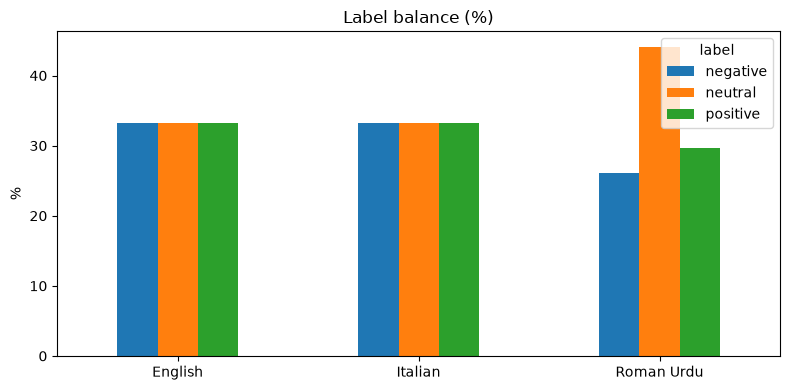

In [3]:
datasets = {'English': en, 'Italian': it, 'Roman Urdu': ru}

balance = pd.DataFrame({
    name: (df['label'].value_counts(normalize=True) * 100).round(1)
    for name, df in datasets.items()
})
print('Percent of each label:')
print(balance)

balance.T.plot.bar(figsize=(8, 4), title='Label balance (%)')
plt.ylabel('%'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. Text length in words (Question 2)

In [4]:
length = pd.DataFrame({
    name: df['text'].astype(str).str.split().str.len().describe().round(1)
    for name, df in datasets.items()
})
print(length)

       English  Italian  Roman Urdu
count   1839.0   1839.0     20228.0
mean      19.6     14.8        13.3
std        4.9      5.8        13.4
min        4.0      1.0         0.0
25%       16.0     10.0         5.0
50%       20.0     15.0         9.0
75%       23.0     19.0        17.0
max       33.0     30.0       301.0


## 4. Roman Urdu spelling variants (Question 3)
How many different spellings of the same word exist in the data?

In [5]:
words = Counter()
for t in ru['text']:
    words.update(re.findall(r"\w+", str(t).lower()))

for canon, variants in VARIANTS.items():
    found = {v: words[v] for v in variants if words[v] > 0}
    print(f"{canon:10s} -> {len(found)} spellings found: {found}")

acha       -> 4 spellings found: {'acha': 384, 'achha': 9, 'accha': 9, 'achcha': 6}
bohot      -> 7 spellings found: {'bohot': 71, 'bohat': 402, 'bahut': 26, 'buhat': 36, 'bhot': 70, 'bht': 300, 'boht': 105}
nahi       -> 6 spellings found: {'nahi': 1076, 'nahin': 47, 'nahe': 66, 'nhi': 369, 'nai': 373, 'nahee': 6}
kharab     -> 4 spellings found: {'kharab': 44, 'kharaab': 3, 'kharb': 1, 'khrab': 11}
bura       -> 3 spellings found: {'bura': 45, 'burra': 2, 'bora': 7}
bekar      -> 3 spellings found: {'bekar': 6, 'bekaar': 7, 'bakwas': 37}
delivery   -> 2 spellings found: {'delivery': 8, 'delivry': 2}
paisa      -> 4 spellings found: {'paisa': 29, 'paisay': 13, 'paise': 15, 'pese': 10}
shukriya   -> 2 spellings found: {'shukriya': 49, 'shukria': 33}
mehenga    -> 3 spellings found: {'mehenga': 1, 'mehnga': 2, 'mehengi': 1}


## 5. Frequent words not yet in the normalizer
If you see Urdu spelling variants here, add them to `VARIANTS` in `src/normalizer.py`.

In [6]:
known = {v for vs in VARIANTS.values() for v in vs}
[(w, c) for w, c in words.most_common(100) if w not in known]

[('ki', 5765),
 ('ke', 5361),
 ('mein', 4369),
 ('hai', 3999),
 ('ka', 3599),
 ('ko', 3585),
 ('se', 3247),
 ('aur', 3186),
 ('k', 2814),
 ('ne', 2060),
 ('to', 1721),
 ('bhi', 1712),
 ('ho', 1697),
 ('hain', 1690),
 ('is', 1661),
 ('kar', 1219),
 ('ye', 1203),
 ('par', 1161),
 ('tha', 1161),
 ('e', 1155),
 ('allah', 1105),
 ('na', 1065),
 ('aik', 1042),
 ('or', 1029),
 ('in', 1023),
 ('wo', 1010),
 ('ha', 1001),
 ('me', 998),
 ('hi', 932),
 ('main', 920),
 ('b', 879),
 ('he', 877),
 ('jo', 867),
 ('kiya', 814),
 ('ap', 798),
 ('hy', 769),
 ('khan', 728),
 ('koi', 710),
 ('pakistan', 707),
 ('kay', 690),
 ('yeh', 688),
 ('the', 685),
 ('h', 654),
 ('kia', 623),
 ('liye', 617),
 ('kr', 610),
 ('un', 599),
 ('thi', 594),
 ('sath', 592),
 ('ya', 547),
 ('aap', 534),
 ('apni', 506),
 ('gaya', 506),
 ('ga', 493),
 ('bad', 488),
 ('tak', 488),
 ('tu', 480),
 ('us', 467),
 ('ab', 465),
 ('kuch', 450),
 ('apne', 422),
 ('say', 419),
 ('ni', 409),
 ('jab', 408),
 ('jis', 407),
 ('per', 399),
 (

## 6. Normalizer demo

In [7]:
samples = ['Bohottt achha service!!!', 'delivery bht late thi, packing kharaab']
[normalize(s) for s in samples]

['bohot acha service', 'delivery bohot late thi packing kharab']

## 7. Summary table (copy this into your notes)

In [8]:
summary = pd.DataFrame({
    'rows': {n: len(d) for n, d in datasets.items()},
    'avg_words': {n: round(d['text'].astype(str).str.split().str.len().mean(), 1) for n, d in datasets.items()},
    'largest_label_%': {n: round(d['label'].value_counts(normalize=True).max() * 100, 1) for n, d in datasets.items()},
})
summary

,rows,avg_words,largest_label_%
English,1839,19.6,33.3
Italian,1839,14.8,33.3
Roman Urdu,20228,13.3,44.1


## My notes (write in your own words)
1. **Label balance:** 
2. **Text length differences:** 
3. **Roman Urdu spelling variants:** 
4. **Problems I noticed in the data:** 

In [13]:
## My notes
##
##1. **Label balance:** Roman Urdu is fairly balanced: neutral 44.1%, positive 29.7%, negative 26.1% (no label above 60%). English: positive [ ]%, neutral [ ]%, negative [ ]%. Italian: positive [ ]%, neutral [ ]%, negative [ ]%. (Fill the `[ ]` from the table in section 2.) Because the classes are not perfectly equal, accuracy alone is not enough; I will also report macro-F1##.

##2. **Text length differences:** Roman Urdu texts are short: mean 13.3 words, median 9, max 301. English: mean [ ] words, max [ ]. Italian: mean [ ] words, max [ ]. (Fill from the table in section 3.) Because lengths differ, I need to choose a max sequence length for the models and check that long texts are not cut too ##much.

##3. **Roman Urdu spelling variants:** The same word is written in many ways. "bohot" appears with 7 spellings (bohat 402, bht 300, boht 105, bohot 71, bhot 70, buhat 36, bahut 26). "nahi" appears with 6 (nahi 1076, nai 373, nhi 369, nahe 66, nahin 47, nahee 6). This confirms that a normalizer is needed before using Roma##n Urdu text in models.

##4. **Problems I noticed in the data:**
   - one label typo ("Neative") fixed
   - about 20,564 lines in the file but 20,228 rows parsed, because some rows contain line breaks or are malformed and were skipped
   - some texts are empty (min length 0)
   - the Roman Urdu dataset has sentiment only, no topic or urgency labels
   - the text is mixed with English words and informal slang
   - the Italian train set is small (1,839 rows)

IndentationError: unexpected indent (2024625957.py, line 10)